# autoPET-V (Part 1): Data Preprocessing, Spatial Alignment & nnU-Net 4-Channel Formatting
### Integration of the DEEP-PSMA PET/CT Subset and Baseline Environment Setup

## 0 — Minimal smoke test
### Modality Loading & Spatial Alignment (CT, PET, Ground Truth)

Shape CT: (512, 512, 335), Spacing: (np.float32(1.074219), np.float32(1.074219), np.float32(3.27))
Shape PET: (192, 192, 335), Spacing: (np.float32(2.8645833), np.float32(2.8645833), np.float32(3.2700002))
Shape Mask: (192, 192, 335)


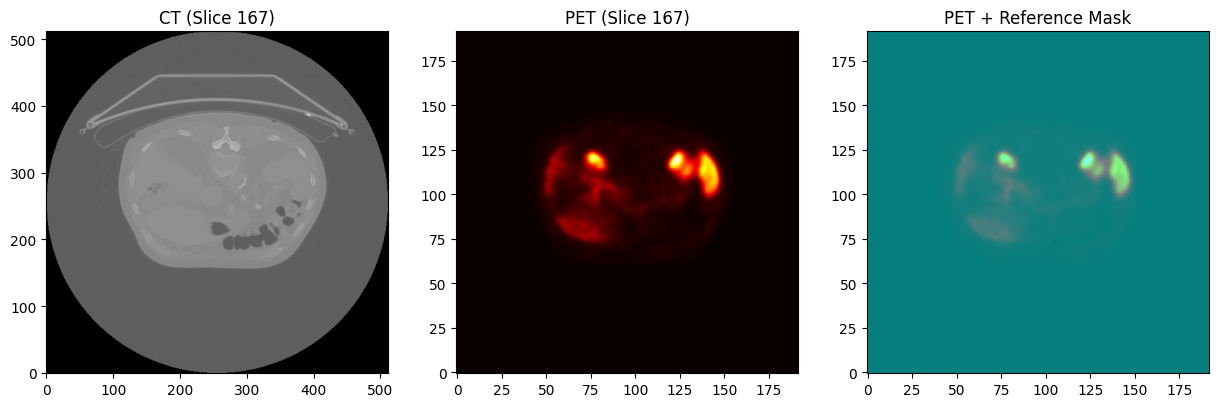

In [1]:
import nibabel as nib
import matplotlib.pyplot as plt
import os

# Synchronized path resolution with fallback for Kaggle mounts
raw_base_dir = "/kaggle/input/datasets/nshichembenmalek/autopet-deep-psma-subset"
if not os.path.exists(raw_base_dir):
    raw_base_dir = "/kaggle/input/autopet-deep-psma-subset"

# Exact paths to Kaggle files for the PSMA tracer of patient train_0001
base_path = os.path.join(raw_base_dir, "train_0001", "PSMA")
ct_path = os.path.join(base_path, "CT.nii")
pet_path = os.path.join(base_path, "PET.nii")
mask_path = os.path.join(base_path, "TTB.nii")

# Load NIfTI volumes
ct_img = nib.load(ct_path)
pet_img = nib.load(pet_path)
mask_img = nib.load(mask_path)

# Display dimensions (CT has a different native resolution than PET; handled during resampling)
print(f"Shape CT: {ct_img.shape}, Spacing: {ct_img.header.get_zooms()}")
print(f"Shape PET: {pet_img.shape}, Spacing: {pet_img.header.get_zooms()}")
print(f"Shape Mask: {mask_img.shape}")

if pet_img.shape != mask_img.shape:
    print("Warning: The reference mask and PET volume do not have the same dimensions!")

# Extract central axial slices
slice_idx_pet = pet_img.shape[2] // 2
slice_idx_ct = ct_img.shape[2] // 2

# Visualization
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title(f"CT (Slice {slice_idx_ct})")
plt.imshow(ct_img.get_fdata()[:, :, slice_idx_ct].T, cmap='gray', origin='lower')

plt.subplot(1, 3, 2)
plt.title(f"PET (Slice {slice_idx_pet})")
plt.imshow(pet_img.get_fdata()[:, :, slice_idx_pet].T, cmap='hot', origin='lower')

plt.subplot(1, 3, 3)
plt.title("PET + Reference Mask")
# Overlay: reference mask ('cool') is displayed over the PET ('hot') with alpha transparency
plt.imshow(pet_img.get_fdata()[:, :, slice_idx_pet].T, cmap='hot', origin='lower')
plt.imshow(mask_img.get_fdata()[:, :, slice_idx_pet].T, cmap='cool', alpha=0.5, origin='lower')

plt.show()

### Environment & Model Weights

In [2]:
import os
import shutil
import subprocess
from pathlib import Path

# 1. Define paths
work_dir = Path("/kaggle/working")
repo_dir = work_dir / "autoPETV"
baseline_dir = repo_dir / "nnunet-baseline"

# 2. Configure nnU-Net
os.environ["nnUNet_raw"] = str(work_dir / "nnUNet_raw")
os.environ["nnUNet_preprocessed"] = str(work_dir / "nnUNet_preprocessed")

for name in ["nnUNet_raw", "nnUNet_preprocessed"]:
    Path(os.environ[name]).mkdir(parents=True, exist_ok=True)

# 3. Clone the official repository if it is not already present
if not repo_dir.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/lab-midas/autoPETV.git",
            str(repo_dir)
        ],
        check=True
    )

# 4. Download and extract the official model weights
check_script = baseline_dir / "check_weights.sh"

if not check_script.is_file():
    raise FileNotFoundError(
        f"Official weight-download script not found: {check_script}"
    )

subprocess.run(
    ["bash", str(check_script)],
    cwd=str(baseline_dir),
    check=True
)

# 5. Find the actual trained checkpoint
checkpoints = list(repo_dir.rglob("checkpoint_final.pth"))

checkpoints = [
    p for p in checkpoints
    if p.stat().st_size > 1_000_000
]

if not checkpoints:
    raise FileNotFoundError(
        "No valid checkpoint_final.pth was found after running "
        "check_weights.sh. Check the download output and Kaggle Internet access."
    )

checkpoint = checkpoints[0]

# The checkpoint is expected under:
# nnUNet_results/Dataset998_AutoPETV/
#   nnUNetTrainer__nnUNetPlans__3d_fullres/fold_0/
source_results = checkpoint.parents[3]

# 6. Put the weights where Part 2 expects them
target_results = baseline_dir / "nnUNet_results"

if source_results.resolve() != target_results.resolve():
    if target_results.exists():
        shutil.rmtree(target_results)

    shutil.copytree(source_results, target_results)

# 7. Verify the final location
final_checkpoint = (
    target_results
    / "Dataset998_AutoPETV"
    / "nnUNetTrainer__nnUNetPlans__3d_fullres"
    / "fold_0"
    / "checkpoint_final.pth"
)

if not final_checkpoint.is_file():
    raise FileNotFoundError(
        f"Checkpoint is not at the expected location: {final_checkpoint}"
    )

print("Model weights successfully prepared.")
print(f"Checkpoint: {final_checkpoint}")
print(f"Checkpoint size: {final_checkpoint.stat().st_size / (1024**2):.1f} MiB")
print(f"Dataset export root: {work_dir}")

Cloning into '/kaggle/working/autoPETV'...


Checking nnUNet model weights...
Checkpoint file is a git-lfs pointer (not downloaded)
This usually means 'git lfs pull' was not run or git-lfs limit was reached.

Attempting to download and extract weights...
Existing weights.zip seems invalid (0MB), re-downloading...
Using gdown for download...


Downloading...
From (original): https://drive.google.com/uc?id=1G0HGHzQMXzslGDxFSNs5fq3RCeAu7M6l
From (redirected): https://drive.google.com/uc?id=1G0HGHzQMXzslGDxFSNs5fq3RCeAu7M6l&confirm=t&uuid=2e6cc517-012f-440e-b935-e5eb7b548115
To: /kaggle/working/autoPETV/nnunet-baseline/weights.zip
100%|██████████| 461M/461M [00:06<00:00, 67.1MB/s] 


Extracting weights...
Removing old nnUNet_results directory...
Extraction successful!
✓ Weights successfully downloaded and extracted!
✓ Checkpoint file size: 235MB

Weight check complete! Ready to proceed.
Model weights successfully prepared.
Checkpoint: /kaggle/working/autoPETV/nnunet-baseline/nnUNet_results/Dataset998_AutoPETV/nnUNetTrainer__nnUNetPlans__3d_fullres/fold_0/checkpoint_final.pth
Checkpoint size: 235.3 MiB
Dataset export root: /kaggle/working


---

## 1 — Preparing a small dataset

### Automated nnU-Net Formatting Script

In [3]:
import os
import glob
import numpy as np
import nibabel as nib
import SimpleITK as sitk

# 1. Define nnU-Net directory structure with mount fallback
base_input = "/kaggle/input/datasets/nshichembenmalek/autopet-deep-psma-subset"
if not os.path.exists(base_input):
    base_input = "/kaggle/input/autopet-deep-psma-subset"

out_dir = "/kaggle/working/Dataset999_AutoPETV"
folders = ["imagesTr", "labelsTr", "imagesTs"]
for f in folders:
    os.makedirs(os.path.join(out_dir, f), exist_ok=True)

# 2. Extract and split patients (10 for development, 10 for evaluation)
patients = sorted(glob.glob(f"{base_input}/train_*"))
dev_patients = patients[:10]
eval_patients = patients[10:20]

def process_cohort(patient_list, img_folder, label_folder=None):
    for pat_path in patient_list:
        pat_id = os.path.basename(pat_path)
        psma_dir = os.path.join(pat_path, "PSMA")
        
        pet_out = os.path.join(out_dir, img_folder, f"{pat_id}_0001.nii.gz")
        ct_out = os.path.join(out_dir, img_folder, f"{pat_id}_0000.nii.gz")
        fg_out = os.path.join(out_dir, img_folder, f"{pat_id}_0002.nii.gz")
        bg_out = os.path.join(out_dir, img_folder, f"{pat_id}_0003.nii.gz")
        
        # 3. Copy PET and Resample CT
        pet_img = sitk.ReadImage(os.path.join(psma_dir, "PET.nii"))
        sitk.WriteImage(pet_img, pet_out)
        
        ct_img = sitk.ReadImage(os.path.join(psma_dir, "CT.nii"))
        resampler = sitk.ResampleImageFilter()
        resampler.SetReferenceImage(pet_img)
        resampler.SetInterpolator(sitk.sitkLinear)
        resampler.SetDefaultPixelValue(-1024)
        resampler.SetTransform(sitk.Transform())
        sitk.WriteImage(resampler.Execute(ct_img), ct_out)
        
        # 4. Generate empty scribble channels
        pet_nib = nib.load(os.path.join(psma_dir, "PET.nii"))
        empty_data = np.zeros(pet_nib.shape, dtype=np.uint8)
        empty_nifti = nib.Nifti1Image(empty_data, pet_nib.affine)
        nib.save(empty_nifti, fg_out)
        nib.save(empty_nifti, bg_out)
        
        # 5. Route reference masks for the development set
        if label_folder:
            label_out = os.path.join(out_dir, label_folder, f"{pat_id}.nii.gz")
            sitk.WriteImage(sitk.ReadImage(os.path.join(psma_dir, "TTB.nii")), label_out)
            
        print(f"Successfully processed {pat_id}")

print("Processing Development Set...")
process_cohort(dev_patients, "imagesTr", "labelsTr")
print("Processing Evaluation Set...")
process_cohort(eval_patients, "imagesTs")
print("Formatting complete.")

Processing Development Set...
Successfully processed train_0001
Successfully processed train_0002
Successfully processed train_0003
Successfully processed train_0004
Successfully processed train_0005
Successfully processed train_0006
Successfully processed train_0007
Successfully processed train_0008
Successfully processed train_0009
Successfully processed train_0010
Processing Evaluation Set...
Successfully processed train_0011
Successfully processed train_0012
Successfully processed train_0013
Successfully processed train_0014
Successfully processed train_0015
Successfully processed train_0016
Successfully processed train_0017
Successfully processed train_0018
Successfully processed train_0019
Successfully processed train_0020
Formatting complete.


### Dataset Export & Partitioning Summary
* **Cohort Division:** 20 patients partitioned into a Development set (10 cases: `train_0001`–`train_0010`) and an Evaluation set (10 cases: `train_0011`–`train_0020`).
* **Channel Configuration:** Conforms to nnU-Net multi-modal input standards:
  * Channel `0000`: CT resampled linearly to PET voxel resolution (background padded to -1024 HU).
  * Channel `0001`: Native PET SUV volume.
  * Channel `0002`: Foreground interactive clicks/scribbles (initialized as empty).
  * Channel `0003`: Background interactive clicks/scribbles (initialized as empty).